# HC3 data exploration

**Project question:** do LLMs build arguments the way humans do?
Part 2 (sections 9-16) checks whether HC3 can support that plan.
Part 1 (sections 1-8) is a general audit of HC3.

## Project findings (Part 2)

No extractor exists yet, so **nothing here is a graph result**.
Any human-vs-LLM difference is `INCONCLUSIVE` until the extractor is checked by hand.

**Use `finance` only**
- All 842 `wiki_csai` questions are `Please explain what is "X"`, so none ask for an opinion.
- `finance` has 228 opinion questions out of 3,932, by a regex filter that the team must still review.

**The human baseline needs FiQA**
- HC3 keeps one human answer per question, so it has no same-question human-vs-human baseline.
- All HC3 `finance` questions and human answers are in FiQA, and 61.9% of questions have 2+ FiQA answers.
- FiQA is tagged CC BY-SA 4.0 on Hugging Face, the same license as HC3.

**The candidate pool is big enough, but only just**
- 68 questions have an opinion question, a usable ChatGPT answer, and two human answers, all of 100-300 words.
- That is enough for 50 questions, with little room if the team rejects many.
- ChatGPT answers are still longer in the pool: median 216.5 words, against 184.5 and 185.

**Sentence splitting would have faked a result**
- 89.7% of `finance` ChatGPT answers have glued sentences (`purposes.An LLC`), against 0.3% of human answers.
- A plain splitter gives ChatGPT a median of 6 nodes. The repaired splitter gives 9, the same as both humans.
- `wiki_csai` does not have this problem (0.0%).
- List structure is only partly recoverable: 20.1% of ChatGPT sentences contain a colon lead-in, against about 3% for humans.
  `GUIDE.md` must decide how to treat them.

**Blind labelling will not be fully blind**
- Formatting can be cleaned, but style cannot.
- First-person words appear in 73.5% and 76.5% of human answers, and 0.0% of ChatGPT answers.
- "It is important to" appears in 55.9% of ChatGPT answers and no human answers.

**Hypotheses for Step 5 (surface cue words, not relations)**
- `example` cues: gap to ChatGPT is larger than the human baseline by 0.066 (95% interval 0.040 to 0.093).
- `restates` cues: larger by 0.022 (0.008 to 0.036).
- `supports`, `attacks`, node count and words per node: no gap beyond the human baseline.
- In the 3 pairs read in section 16, ChatGPT lists considerations and ends with a general summary.
  The humans more often take a position. This is one reading of 3 examples, not a measurement.

**Limits**
- One regex for opinion questions, one ChatGPT version, one seed.
- Six cue tests with no multiple-testing correction.
- Human B is the FiQA answer closest in length to human A, not a random one.
- Some human answers depend on context that is gone, such as "All great answers." or a removed link.

**Data versions:** HC3 `4d0ff18`, BeIR/fiqa `979c07a`, BeIR/fiqa-qrels `252958f`.

## General HC3 audit (Part 1)

**Human ChatGPT Comparison Corpus (HC3):** questions paired with human answers and ChatGPT answers, across five sources.

After cleaning there are **79,219 answers**: 53,060 human and 26,159 ChatGPT. The dataset has no timestamps.

**Data quality**
- **Loading:** the original cell failed because `datasets` no longer runs `HC3.py`. The raw `all.jsonl` loads fine.
- **Imbalance:** Reddit is 78% of all answers, so pooled numbers mostly describe Reddit. The human share ranges from 25% (open_qa) to 75% (reddit_eli5).
- **Mislabelled text:** 198 "ChatGPT answers" are scraped web-UI messages such as rate-limit and network errors. There are also 18 empty answers and 39 containing Chinese characters.
- **Duplicates:** 5,973 answers (7%) are exact repeats, nearly all on Reddit. 830 questions appear twice, and 455 Reddit rows have no ChatGPT answer.
- **Refusals:** about 380 ChatGPT answers (1.4%) are refusals or AI disclaimers. They are real output, so they stay in and are flagged.

**Formatting gives the label away**
- Reddit human text is pre-tokenised (` n't`, ` .`) and ChatGPT text isn't. "Space before punctuation means human" scores **99.3%** balanced accuracy on Reddit and 94.0% overall, without reading a single word.
- Line breaks, `URL_0` placeholders, double spaces and literal `\\n` strings also differ by label.

**The real signal survives without those shortcuts**
- Removing them only takes a simple classifier from 99.4% to **98.3%**. Fourteen style features alone still reach 93.5%. Formatting is enough to separate the classes, but it isn't what makes them separable.
- **Length:** ChatGPT is longer on the same question 88-97% of the time on reddit_eli5, medicine and open_qa, but only 55% on wiki_csai. It never exceeds 639 words, while humans reach 6,208.
- **Style:** ChatGPT reuses the question's words, hedges more, and varies sentence length less. Its vocabulary is also less varied, and that is the one difference that holds in all five sources.
- **Stock phrases:** "it's important to" appears in 16.9% of ChatGPT answers vs 0.3% of human answers. "Overall," appears in 10.6% vs 0.1%. "I think" goes the other way, 0.1% vs 3.4%.

**Detection doesn't transfer evenly**
- wiki_csai is the hardest source, because encyclopedic human writing resembles ChatGPT. Holding it out of training drops accuracy from 91.3% to **71.7%**, and 56% of its human answers get flagged as ChatGPT.
- Its AUC stays at 0.948, so the ranking mostly survives and the decision threshold is what fails to transfer.
- reddit_eli5 (98.6% to 87.4%) and open_qa (92.6% to 83.2%) also drop. finance and medicine barely move.

**For any model built on this**
- Use `clean` and `norm`, split by question, report per source, and test on a held-out source.

**Caveats**
- The Part 1 `style` features use a plain splitter that misses glued ChatGPT sentences (section 12). Finance words-per-sentence AUC falls from 0.928 to 0.743 once repaired, so the "14 style features" score may be inflated, and it was not re-run. Lower sentence length variation still holds in all five sources.
- Classifier numbers come from one split with one seed, so small gaps between rows aren't meaningful, especially on wiki_csai (about 320 test answers).
- Each source's human side is its own genre (doctors, Wikipedia, Reddit), so differences mix author and genre.
- Scraped text mentions "ChatGPT Dec 15 Version", so this reflects an early ChatGPT and may not hold for current models.

## 1. Load

In [1]:
from datasets import load_dataset

# HC3.py is a loading script, which current `datasets` refuses to run, so read the raw JSONL instead.
ds = load_dataset("json", data_files="hf://datasets/Hello-SimpleAI/HC3/all.jsonl", split="train")
ds

/Users/aiman/Projects/claude-impact-lab/claude-hackathon-berlin-2026/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset({
    features: ['question', 'human_answers', 'chatgpt_answers', 'index', 'source'],
    num_rows: 24322
})

In [2]:
df = ds.to_pandas()  # a Dataset has no .head()
df.head()

,question,human_answers,chatgpt_answers,index,source
0,"Why is every book I hear about a "" NY Times # ...","[Basically there are many categories of "" Best...",[There are many different best seller lists th...,NaN,reddit_eli5
1,"If salt is so bad for cars , why do we use it ...",[salt is good for not dying in car crashes and...,[Salt is used on roads to help melt ice and sn...,NaN,reddit_eli5
2,Why do we still have SD TV channels when HD lo...,[The way it works is that old TV stations got ...,[There are a few reasons why we still have SD ...,NaN,reddit_eli5
3,Why has nobody assassinated Kim Jong - un He i...,[You ca n't just go around assassinating the l...,[It is generally not acceptable or ethical to ...,NaN,reddit_eli5
4,How was airplane technology able to advance so...,[Wanting to kill the shit out of Germans drive...,[After the Wright Brothers made the first powe...,NaN,reddit_eli5


In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline

pd.set_option("display.max_colwidth", 120, "display.width", 160)
HUMAN, GPT, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"
COLORS = {"human": HUMAN, "chatgpt": GPT}
SOURCES = ["reddit_eli5", "finance", "medicine", "open_qa", "wiki_csai"]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})

## 2. Structure

One row per question. `human_answers` and `chatgpt_answers` are lists, so the row count is not the answer count.

In [4]:
counts = lambda col: df[col].map(len)
pd.DataFrame({
    "questions": df.groupby("source").size(),
    "human_answers": counts("human_answers").groupby(df.source).sum(),
    "chatgpt_answers": counts("chatgpt_answers").groupby(df.source).sum(),
    "questions_with_no_chatgpt": counts("chatgpt_answers").eq(0).groupby(df.source).sum(),
    "index_filled": df["index"].notna().groupby(df.source).sum(),
}).loc[SOURCES]

,questions,human_answers,chatgpt_answers,questions_with_no_chatgpt,index_filled
source,,,,,
reddit_eli5,17112,51336,16660,455,2521
finance,3933,3933,4503,0,0
medicine,1248,1248,1337,0,0
open_qa,1187,1187,3561,0,0
wiki_csai,842,842,842,0,0


In [5]:
pd.crosstab(df.source, [counts("human_answers").rename("human per question")]).join(
    pd.crosstab(df.source, counts("chatgpt_answers").rename("chatgpt")).add_prefix("chatgpt="), how="outer").loc[SOURCES]

,1,3,chatgpt=0,chatgpt=1,chatgpt=2,chatgpt=3
source,,,,,,
reddit_eli5,0,17112,455,16654,3,0
finance,3933,0,0,3363,570,0
medicine,1248,0,0,1175,57,16
open_qa,1187,0,0,0,0,1187
wiki_csai,842,0,0,842,0,0


In [6]:
# Questions: templating and length differ a lot by source.
q = df.assign(q_words=df.question.str.split().str.len(),
              first_word=df.question.str.lower().str.extract(r"^\W*(\w+)", expand=False))
display(q.groupby("source").q_words.describe(percentiles=[.5, .99]).round(0).loc[SOURCES])
display(q.groupby("source").first_word.agg(lambda s: ", ".join(f"{k} {v:.0%}" for k, v in s.value_counts(normalize=True).head(4).items())).loc[SOURCES].to_frame("most common first words"))
print(f"ELI5 questions containing an 'explain like I'm five' suffix: {df[df.source == 'reddit_eli5'].question.str.contains('Explain like I.m five|explain like I.m five').mean():.0%}")

,count,mean,std,min,50%,99%,max
source,,,,,,,
reddit_eli5,17112.0,38.0,10.0,15.0,39.0,54.0,54.0
finance,3933.0,11.0,4.0,2.0,10.0,23.0,31.0
medicine,1248.0,67.0,13.0,17.0,67.0,92.0,97.0
open_qa,1187.0,6.0,2.0,2.0,6.0,12.0,17.0
wiki_csai,842.0,6.0,0.0,6.0,6.0,7.0,7.0


,most common first words
source,
reddit_eli5,"why 40%, how 19%, what 14%, the 4%"
finance,"how 15%, what 13%, why 6%, is 6%"
medicine,"what 34%, suggest 16%, is 9%, how 7%"
open_qa,"what 54%, how 14%, who 13%, where 9%"
wiki_csai,please 100%


ELI5 questions containing an 'explain like I'm five' suffix: 100%


## 3. Data quality

Explode to one row per answer, then check what is actually in the text.

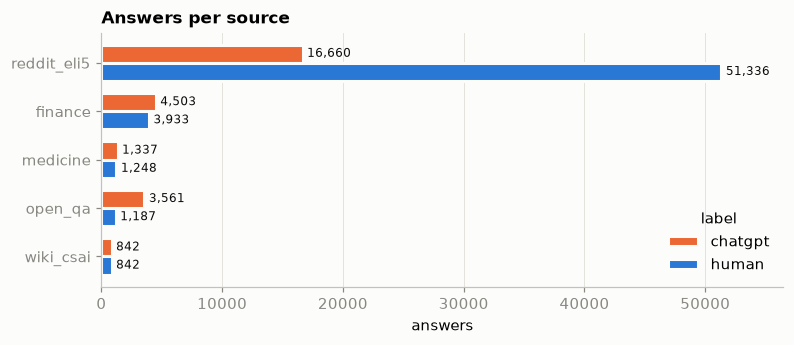

85,449 answers; human share 69%
source
reddit_eli5    75%
finance        47%
medicine       48%
open_qa        25%
wiki_csai      50%


In [7]:
raw = pd.concat([
    df[["question", "source", col]].explode(col).rename(columns={col: "text"}).assign(label=label)
    for col, label in [("human_answers", "human"), ("chatgpt_answers", "chatgpt")]
]).dropna(subset="text").reset_index(drop=True)

raw.groupby(["source", "label"]).size().unstack().loc[SOURCES].plot.barh(
    color=[GPT, HUMAN], width=.75, edgecolor="#fcfcfb", linewidth=2, figsize=(8, 3), title="Answers per source").invert_yaxis()
ax = plt.gca(); ax.grid(axis="y", visible=False); ax.set(xlabel="answers", ylabel="")
for c in ax.containers: ax.bar_label(c, fmt="{:,.0f}", padding=3, color=INK, fontsize=8)
ax.margins(x=.1); plt.show()
print(f"{len(raw):,} answers; human share {raw.label.eq('human').mean():.0%}")
print(raw.groupby("source").label.apply(lambda s: s.eq("human").mean()).loc[SOURCES].map("{:.0%}".format).to_string())

In [8]:
# ChatGPT "answers" that are really scraped web-UI messages.
ERROR = (r"There was an error generating|Too many requests|network error|authentication token|Only one message at a time"
         r"|Checking if the site connection|needs to review the security|Free Research Preview|Regenerate response")
REFUSAL = r"(?i)^(?:i'm sorry, but|i am sorry, but|sorry, but)|as an ai\b|language model"

raw["is_error"] = raw.label.eq("chatgpt") & raw.text.str.contains(ERROR)
raw["is_empty"] = raw.text.str.strip().eq("")
raw["is_cjk"] = raw.text.str.contains(r"[\u4e00-\u9fff]")
raw["is_refusal"] = raw.label.eq("chatgpt") & raw.text.str.contains(REFUSAL)
raw["stray_prefix"] = raw.text.str.match(r"^[!,\s\u200b]*!")
raw["literal_backslash_n"] = raw.text.str.contains(r"\\n")

flags = ["is_error", "is_empty", "is_cjk", "is_refusal", "stray_prefix", "literal_backslash_n"]
display(raw.groupby(["label", "source"])[flags].sum().query("is_error + is_empty + is_cjk + is_refusal + stray_prefix + literal_backslash_n > 0"))
raw[raw.is_error].text.str[:100].value_counts().head(8).to_frame("copies")

is_error  is_empty  is_cjk  is_refusal  stray_prefix  literal_backslash_n
label   source                                                                                
chatgpt finance            58         0       1          59            40                    1
        medicine           35         3       1          31            32                    1
        open_qa             7        15       3          70             7                 1331
        reddit_eli5        97         0       7         208            40                 1820
        wiki_csai           1         0       0          16             1                    0
human   finance             0         0       1           0             0                    0
        open_qa             0         0       2           0             0                    0
        reddit_eli5         0         0      24           0             0                    0
        wiki_csai           0         0       1           0             0                    1

,copies
text,
​\r\n\r\n\r\n···\r\nChatGPT Dec 15 Version. Free Research Preview. Our goal is to make AI systems more natur,51
!\nToo many requests in 1 hour. Try again later.\n\n\n\nThere was an error generating a response,27
chat.openai.comChecking if the site connection is securechat.openai.com needs to review the security,26
!Your authentication token has expired. Please try signing in again.There was an error generating a,24
!Only one message at a time. Please allow any other responses to complete before sending another mes,15
!\nnetwork error\n\n\n\nThere was an error generating a response,8
!network errorThere was an error generating a response,7
"!, network error, There was an error generating a response",5


In [9]:
# Duplicates. The same question appears on two rows, sometimes with the ChatGPT answer on only one of them.
hashable = df.assign(h=df.human_answers.map(lambda a: "|".join(sorted(a))), c=df.chatgpt_answers.map(lambda a: "|".join(sorted(a))))
print("repeated questions:", df.question.duplicated().sum(), "| sources:", df[df.question.duplicated()].source.unique().tolist())
print("fully identical rows:", hashable.duplicated(["question", "h", "c"]).sum())
print("repeated questions with no ChatGPT answer on a copy:", df[df.question.duplicated(keep=False)].chatgpt_answers.map(len).eq(0).sum())
print("same human answer under different questions:", raw[raw.label.eq("human")].groupby("text").question.nunique().gt(1).sum())
display(raw.assign(dup=raw.duplicated(["label", "text"])).groupby(["source", "label"]).dup.sum().unstack().loc[SOURCES])
print("`index` is filled on rows", df.index[df["index"].notna()].min(), "to", df.index[df["index"].notna()].max(), "- a leftover ID from one ELI5 batch, not a feature")

repeated questions: 830 | sources: ['reddit_eli5']
fully identical rows: 509
repeated questions with no ChatGPT answer on a copy: 307
same human answer under different questions: 2958


label,chatgpt,human
source,,
reddit_eli5,538,5371
finance,43,0
medicine,34,2
open_qa,42,16
wiki_csai,0,71


`index` is filled on rows 1607 to 4127 - a leftover ID from one ELI5 batch, not a feature


In [10]:
# Formatting differs by label because the sources were processed differently, not because the authors wrote differently.
ARTIFACTS = {
    "space before punctuation": r" [.,?!;:](?: |$)", "split contraction ( n't)": r" n't\b", "URL_n placeholder": r"URL_\d+",
    "spaced bracket ( ( )": r" \( ", "real newline": r"\n", "double space": r"  ", "[n] citation": r"\[\d+\]",
}
artifacts = pd.DataFrame({k: raw.text.str.contains(v).groupby([raw.source, raw.label]).mean() for k, v in ARTIFACTS.items()})
artifacts.loc[SOURCES].style.format("{:.0%}").background_gradient(cmap=LinearSegmentedColormap.from_list("b", ["#fcfcfb", "#6da7ec"]), vmin=0, vmax=1)

## 4. Cleaning

- **Drop:** scraped error pages, empty answers, answers containing Chinese characters, and exact duplicates. Duplicates are matched on label and text, which also merges the repeated questions.
- **Keep:** refusals, because they are real ChatGPT output. They stay flagged.
- **Normalise:** `norm` undoes tokenisation, placeholders and line breaks, so that analysis compares writing rather than preprocessing.

In [11]:
def normalise(s):
    for pattern, repl in [
        (r"\\[nr]", " "), ("\u2019", "'"), (r"^[!,\s\u200b]+", ""), (r"URL_\d+", " "), (r"\[\d+\]", ""),
        (r"\s+(n't|'s|'re|'ve|'ll|'d|'m)\b", r"\1"), (r"\s+([.,?!;:)\]])", r"\1"), (r"([(\[])\s+", r"\1"),
        (r'"\s*([^"]*?)\s*"', r'"\1"'), (r"(?<=\w) - (?=\w)", "-"), (r"\s+", " "),
    ]:
        s = s.str.replace(pattern, repl, regex=True)
    return s.str.strip()

assert normalise(pd.Series(["!It do n't work , see ( URL_0 ) .\\n a well - known \" thing \""]))[0] == """It don't work, see (). a well-known "thing\""""

steps = [("raw answers", len(raw))]
clean = raw
for name, mask in [("error pages", clean.is_error), ("empty", clean.is_empty), ("Chinese text", clean.is_cjk)]:
    clean = clean[~mask.reindex(clean.index)]
    steps.append((f"after dropping {name}", len(clean)))
clean = clean.drop_duplicates(["label", "text"]).copy()
steps.append(("after dropping exact duplicates", len(clean)))
clean["norm"] = normalise(clean.text)
clean = clean[clean.norm.ne("")]
steps.append(("after normalising", len(clean)))
display(pd.DataFrame(steps, columns=["step", "answers"]).assign(removed=lambda d: -d.answers.diff().fillna(0).astype(int)))
clean.groupby(["source", "label"]).size().unstack().loc[SOURCES]

,step,answers,removed
0,raw answers,85449,0
1,after dropping error pages,85251,198
2,after dropping empty,85233,18
3,after dropping Chinese text,85194,39
4,after dropping exact duplicates,79221,5973
5,after normalising,79219,2


label,chatgpt,human
source,,
reddit_eli5,16064,45943
finance,4442,3932
medicine,1299,1246
open_qa,3513,1169
wiki_csai,841,770


In [12]:
# Spot check: one random answer pair per source.
for s in SOURCES:
    x = clean[clean.source == s]
    pair = x[x.question.isin(set(x[x.label == "human"].question) & set(x[x.label == "chatgpt"].question))].sample(1, random_state=1).question.iloc[0]
    print(f"--- {s}\nQ: {pair[:160]}")
    for l in ["human", "chatgpt"]: print(f"  {l}: {x[(x.question == pair) & (x.label == l)].norm.iloc[0][:260]}")

--- reddit_eli5
Q: Why does observing a particle change it ? Could this suggest that our minds are influencing reality or is it something else ? Explain like I'm five. 
  human: You have to think about what "observe" means in this context. On a large scale we assume that the miniscule energy in light isn't sufficient to actually alter the behavior of an object. The position of the sun won't have much impact on a baseball's trajectory.
  chatgpt: Observing a particle can change it because the act of observation involves interacting with the particle in some way. For example, if you want to see where a particle is, you might shine a light on it or bounce another particle off of it. These interactions ca
--- finance
Q: Did basically all mutual funds have a significant crash in 2008?
  human: The literal answer to your question is that a number of different types of mutual funds did not have significant downturns in 2008. Money Market Funds are intended to always preserve capital. VMMXX ma

## 5. Answer length

Human answers have a long right tail and ChatGPT's stop at a few hundred words. The x-axes are log-scaled, and every source has its own panel because they differ so much.

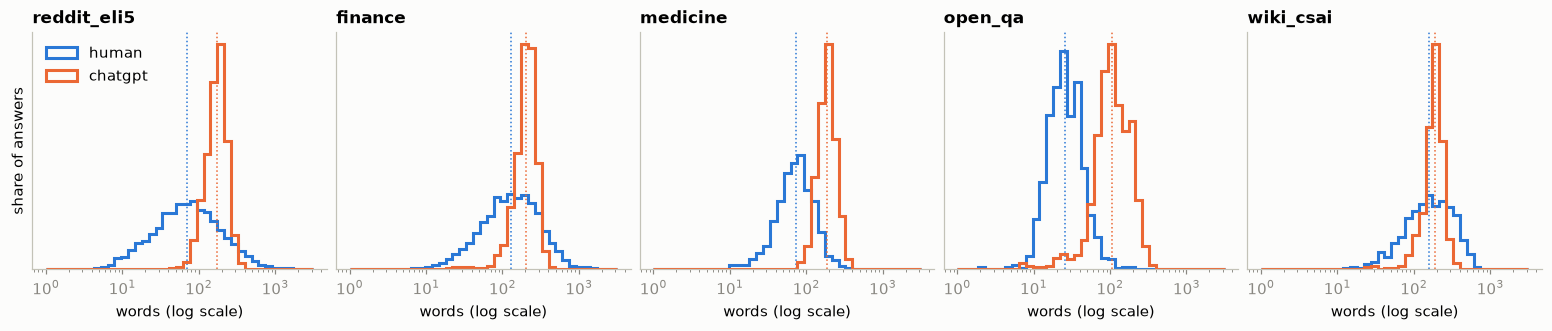

median           iqr           p99           max      
label       chatgpt human chatgpt human chatgpt human chatgpt human
source                                                             
reddit_eli5     174    71      70   103     317   704     639  6208
finance         206   128      76   157     361   746     550  1621
medicine        186    73      64    52     343   238     407   363
open_qa         107    26      80    17     289    98     613   193
wiki_csai       188   160      60   168     320   575     373   695

In [13]:
clean["words"] = clean.norm.str.split().str.len()
fig, axes = plt.subplots(1, 5, figsize=(14, 2.9), sharex=True, layout="constrained")
bins = np.logspace(0, 3.5, 40)
for ax, s in zip(axes, SOURCES):
    for label, c in COLORS.items():
        x = clean[(clean.source == s) & (clean.label == label)].words
        ax.hist(x, bins=bins, weights=np.full(len(x), 1 / len(x)), histtype="step", color=c, linewidth=2, label=label)
        ax.axvline(x.median(), color=c, linewidth=1, linestyle=":")
    ax.set(xscale="log", title=s, xlabel="words (log scale)", yticks=[])
    ax.grid(False)
axes[0].set_ylabel("share of answers"); axes[0].legend(loc="upper left")
plt.show()

g = clean.groupby(["source", "label"]).words
table = pd.DataFrame({"median": g.median(), "iqr": g.quantile(.75) - g.quantile(.25), "p99": g.quantile(.99), "max": g.max()}).astype(int).unstack().loc[SOURCES]
table

In [14]:
# Paired view: same question, median human answer vs median ChatGPT answer.
per_q = clean.groupby(["source", "question", "label"]).words.median().unstack().dropna()
paired = per_q.assign(gpt_longer=per_q.chatgpt > per_q.human, ratio=per_q.chatgpt / per_q.human).groupby("source")
pd.DataFrame({"paired_questions": paired.size(), "chatgpt_longer": paired.gpt_longer.mean().map("{:.0%}".format), "median_length_ratio": paired.ratio.median().round(2)}).loc[SOURCES]

,paired_questions,chatgpt_longer,median_length_ratio
source,,,
reddit_eli5,15078,88%,2.36
finance,3905,68%,1.54
medicine,1232,96%,2.50
open_qa,1168,97%,4.06
wiki_csai,769,55%,1.12


## 6. Writing style

Features are computed on `norm`, so tokenisation can't affect them. Each cell is an AUC: the chance a random ChatGPT answer scores higher than a random human answer. **0.5 means no difference.** With samples this large nearly everything is statistically significant, so effect size is the useful measure.

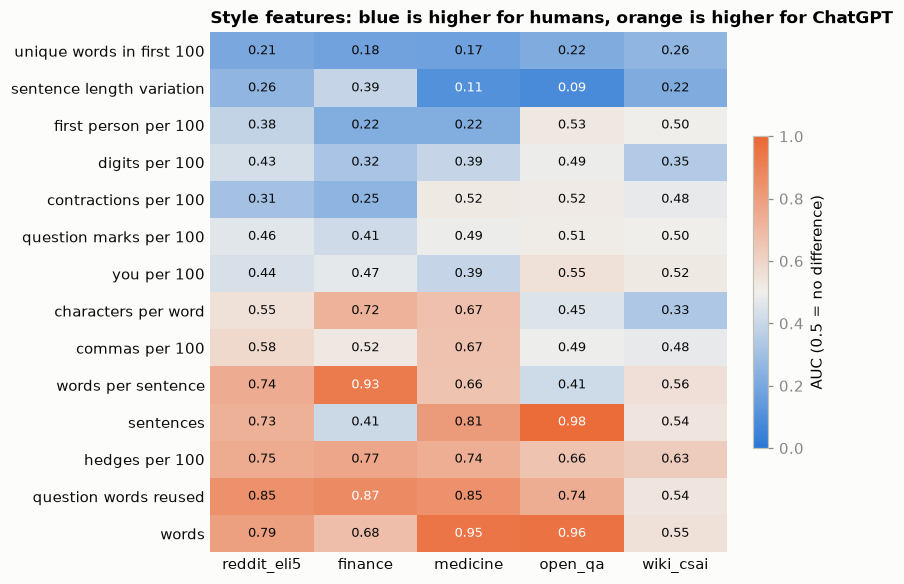

In [15]:
WORD, SENT = re.compile(r"[a-z0-9']+"), re.compile(r"(?<=[.!?])\s+")
FIRST = {"i", "i'm", "i've", "i'd", "i'll", "me", "my", "mine", "we", "our", "us"}
HEDGE = {"may", "might", "could", "generally", "typically", "often", "possible", "usually", "can"}
STOP = set(CountVectorizer(stop_words="english").get_stop_words())
q_clean = lambda q: set(w for w in WORD.findall(q.lower()) if w not in STOP and len(w) > 3)

def style(text, question):
    w = WORD.findall(text.lower()); n = max(len(w), 1)
    sents = [len(s.split()) for s in SENT.split(text) if s.strip()] or [0]
    qw = q_clean(question)
    return {
        "sentences": len(sents), "words per sentence": np.mean(sents),
        "sentence length variation": np.std(sents) / max(np.mean(sents), 1) if len(sents) > 2 else np.nan,
        "characters per word": sum(map(len, w)) / n,
        "unique words in first 100": len(set(w[:100])) if n >= 100 else np.nan,
        "first person per 100": 100 * sum(x in FIRST for x in w) / n,
        "you per 100": 100 * sum(x in {"you", "your", "you're"} for x in w) / n,
        "hedges per 100": 100 * sum(x in HEDGE for x in w) / n,
        "contractions per 100": 100 * sum("'" in x and not x.endswith("'s") for x in w) / n,
        "commas per 100": 100 * text.count(",") / n,
        "question marks per 100": 100 * text.count("?") / n,
        "digits per 100": 100 * sum(c.isdigit() for c in text) / n,
        "question words reused": len(qw & set(w)) / len(qw) if qw else np.nan,
    }

feats = pd.DataFrame([style(t, q) for t, q in zip(clean.norm, clean.question)], index=clean.index).assign(words=clean.words)
y = clean.label.eq("chatgpt")

def auc(col, src):
    m = clean.source.eq(src) & feats[col].notna()
    return roc_auc_score(y[m], feats.loc[m, col])
aucs = pd.DataFrame({s: {c: auc(c, s) for c in feats} for s in SOURCES})
aucs = aucs.loc[aucs.sub(.5).mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7.5, 5.2), layout="constrained")
cmap = LinearSegmentedColormap.from_list("div", [HUMAN, "#f0efec", GPT])
im = ax.imshow(aucs, cmap=cmap, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(5), SOURCES); ax.set_yticks(range(len(aucs)), aucs.index, color=INK); ax.tick_params(length=0, colors=INK); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
for (i, j), v in np.ndenumerate(aucs.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v - .5) > .36 else INK)
ax.set_title("Style features: blue is higher for humans, orange is higher for ChatGPT")
fig.colorbar(im, ax=ax, shrink=.6, label="AUC (0.5 = no difference)")
plt.show()

In [16]:
# Medians behind the heatmap, for the features that hold up across sources.
keep = ["words per sentence", "sentence length variation", "unique words in first 100", "first person per 100", "contractions per 100", "hedges per 100", "question words reused"]
feats[keep].join(clean[["source", "label"]]).groupby(["source", "label"]).median().round(2).loc[SOURCES]

words per sentence  sentence length variation  unique words in first 100  first person per 100  contractions per 100  hedges per 100  \
source      label                                                                                                                                           
reddit_eli5 chatgpt               22.25                       0.32                       61.0                  0.00                  0.00            2.15   
            human                 17.00                       0.47                       69.0                  0.00                  0.60            0.33   
finance     chatgpt               35.50                       0.41                       60.0                  0.00                  0.00            2.47   
            human                 19.00                       0.47                       68.0                  0.76                  0.63            1.06   
medicine    chatgpt               21.57                       0.30                       65.0                  0.00                  0.00            3.16   
            human                 15.33                       0.59                       72.0                  1.69                  0.00            1.82   
open_qa     chatgpt               21.50                       0.29                       61.0                  0.00                  0.00            0.00   
            human                 24.00                       0.63                       67.0                  0.00                  0.00            0.00   
wiki_csai   chatgpt               24.00                       0.26                       61.0                  0.00                  0.00            1.36   
            human                 23.00                       0.41                       66.0                  0.00                  0.00            0.78   

                     question words reused  
source      label                           
reddit_eli5 chatgpt                   0.43  
            human                     0.18  
finance     chatgpt                   0.82  
            human                     0.33  
medicine    chatgpt                   0.28  
            human                     0.12  
open_qa     chatgpt                   1.00  
            human                     0.50  
wiki_csai   chatgpt                   0.67  
            human                     0.67

## 7. Vocabulary and stock phrases

Log-odds are computed separately per source and then averaged, so Reddit doesn't dominate. Only words used in all five sources are eligible, which keeps out topic words.

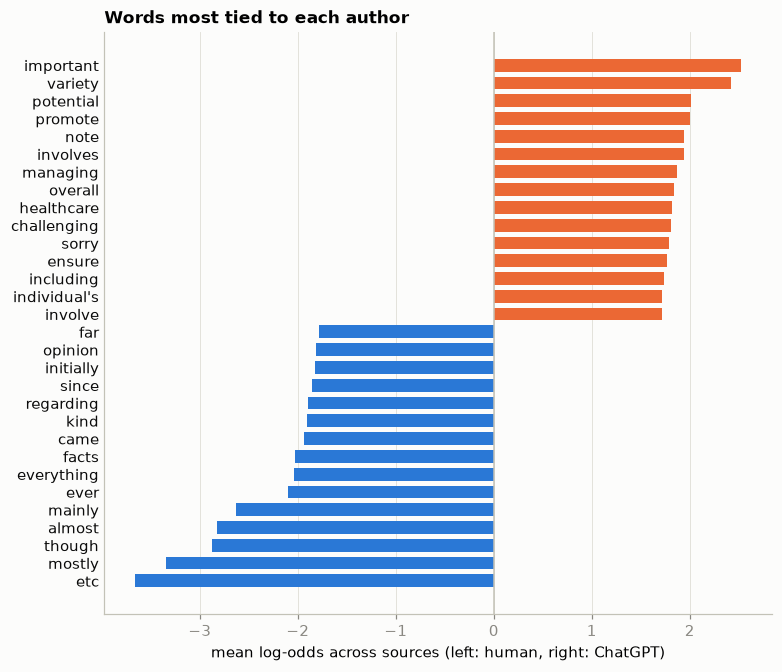

,most distinctive words (includes topic words)
reddit_eli5 human,"nt, i've, it'll, info, everybody, they'd, kinda, yeah"
reddit_eli5 chatgpt,"cannot, multifaceted, cryptocurrencies, jesus', nectar, states', workers', parents'"
finance human,"http, i've, pretty, maybe, whatever, basically, aren't, wouldn't"
finance chatgpt,"personalized, alerts, outlines, complying, linux, creditworthiness, amenities, misunderstandings"
medicine human,"dr, thanks, regards, answered, welcome, query, hcm, magic"
medicine chatgpt,"provider, address, contribute, determine, managing, digestive, potential, speak"
open_qa human,"twenty, nation's, ventricular, ml, literally, formerly, describes, premature"
open_qa chatgpt,"important, note, healthcare, medications, tools, activities, i'm, find"
wiki_csai human,"displaystyle, thus, december, october, january, april, sub, july"
wiki_csai chatgpt,"diagnose, shortest, revolutionize, recommendations, adjusting, promote, i'm, sorry"


In [17]:
def log_odds(frame):
    vec = CountVectorizer(token_pattern=r"[a-z][a-z']+", min_df=5)
    X = vec.fit_transform(frame.norm.str.lower())
    is_gpt = frame.label.eq("chatgpt").to_numpy()
    g, h = np.asarray(X[is_gpt].sum(0)).ravel() + .5, np.asarray(X[~is_gpt].sum(0)).ravel() + .5
    return pd.Series(np.log(g / g.sum()) - np.log(h / h.sum()), vec.get_feature_names_out())

odds = pd.DataFrame({s: log_odds(clean[clean.source == s]) for s in SOURCES})
shared = odds.dropna()
mean = shared.mean(axis=1).sort_values()
top = pd.concat([mean.head(15), mean.tail(15)])

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ax.barh(top.index, top, color=[HUMAN if v < 0 else GPT for v in top], height=.72)
ax.axvline(0, color="#c3c2b7", linewidth=1); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", colors=INK, length=0)
ax.set(xlabel="mean log-odds across sources (left: human, right: ChatGPT)", title="Words most tied to each author")
plt.show()

pd.DataFrame({f"{s} {side}": list((odds[s].dropna().sort_values().index[:8] if side == "human" else odds[s].dropna().sort_values().index[-8:][::-1]))
              for s in SOURCES for side in ["human", "chatgpt"]}).T.agg(", ".join, axis=1).to_frame("most distinctive words (includes topic words)")

In [18]:
# Stock phrases and openings.
PHRASES = ["it is important to", "it's important to", "however,", "additionally,", "overall,", "in general,", "there are several", "for example,", "i think", "i'm not sure", "lol", "good luck"]
low = clean.norm.str.lower()
phrases = pd.DataFrame({p: low.str.contains(re.escape(p)).groupby(clean.label).mean() for p in PHRASES}).T[["human", "chatgpt"]]
display(phrases.assign(ratio=lambda d: (d.chatgpt / d.human).round(1)).style.format({"human": "{:.1%}", "chatgpt": "{:.1%}", "ratio": "{:.1f}x"}))

opener = clean.norm.str.split().str[:2].str.join(" ")
print("Share of answers using that author's 20 most common two-word openings:")
print(opener.groupby(clean.label).apply(lambda s: s.value_counts(normalize=True).head(20).sum()).map("{:.1%}".format).to_string())
display(opener.groupby(clean.label).apply(lambda s: ", ".join(s.value_counts().head(8).index)).to_frame("top openings"))
print("Source-specific boilerplate left in human text:")
print(f"  medicine answers naming a doctor: {clean[(clean.source == 'medicine') & (clean.label == 'human')].norm.str.contains(r'Dr[.]? [A-Z]').mean():.0%}")
print(f"  medicine answers with a greeting: {clean[(clean.source == 'medicine') & (clean.label == 'human')].norm.str.contains(r'(?i)^(?:hi|hello|thanks|thank you|welcome)').mean():.0%}")

label,human,chatgpt,ratio
it is important to,0.1%,12.4%,109.9x
it's important to,0.3%,16.9%,66.8x
"however,",4.7%,21.6%,4.6x
"additionally,",0.4%,5.0%,12.8x
"overall,",0.1%,10.6%,89.4x
"in general,",0.5%,4.1%,9.1x
there are several,0.4%,4.7%,13.4x
"for example,",3.7%,18.0%,4.9x
i think,3.4%,0.1%,0.0x
i'm not sure,0.6%,0.1%,0.1x


Share of answers using that author's 20 most common two-word openings:
label
chatgpt    25.1%
human      10.4%


,top openings
label,
chatgpt,"There are, It is, When you, In the, I'm sorry,, If you, It's not, I'm sorry"
human,"There are, I think, If you, This is, It is, There is, It's a, In the"


Source-specific boilerplate left in human text:
  medicine answers naming a doctor: 25%
  medicine answers with a greeting: 82%


## 8. How much of the signal is real?

Each step removes one shortcut from a simple TF-IDF and logistic regression detector. The drop between steps shows what that shortcut was worth.

The metric is balanced accuracy, because humans outnumber ChatGPT 3 to 1 on Reddit. Splits are grouped by question from step 2 onward, so a question's answers never appear on both sides.

In [19]:
# A one-line rule first: tokenised punctuation alone, on the uncleaned text.
rule = raw.text.str.contains(r" [.,?!;:](?: |$)")
print("Rule 'space before punctuation means human':")
print(raw.groupby("source").apply(lambda d: balanced_accuracy_score(d.label.eq("human"), rule[d.index]), include_groups=False).loc[SOURCES].map("{:.1%}".format).to_string())
print(f"all sources: {balanced_accuracy_score(raw.label.eq('human'), rule):.1%}")

Rule 'space before punctuation means human':
source
reddit_eli5    99.3%
finance        51.0%
medicine       55.7%
open_qa        79.7%
wiki_csai      50.1%
all sources: 94.0%


In [20]:
def model(**vec):
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True, **vec),
                         LogisticRegression(C=10, max_iter=500, class_weight="balanced"))
as_written = dict(token_pattern=r"\S+|\n", lowercase=False)  # keeps " ." and newlines as tokens
words_only = dict(token_pattern=r"[a-z][a-z']+", lowercase=True)

def score(fitted, X, y, src):
    p = fitted.predict_proba(X)[:, 1]
    res = {"all": balanced_accuracy_score(y, p > .5), "AUC": roc_auc_score(y, p)}
    return res | {s: balanced_accuracy_score(y[src == s], p[src == s] > .5) for s in SOURCES}

def run(frame, col, vec, groups):
    y, src = frame.label.eq("chatgpt").to_numpy(), frame.source.to_numpy()
    tr, te = next(group.split(frame, groups=groups))
    X = frame[col].to_numpy()
    fitted = model(**vec).fit(X[tr], y[tr])
    return fitted, score(fitted, X[te], y[te], src[te])

group = GroupShuffleSplit(1, test_size=.2, random_state=0)
results = {}
unique_rows = raw[~raw.is_empty]
_, results["1. raw data, random split"] = run(unique_rows, "text", as_written, np.arange(len(unique_rows)))  # one group per row = random split
_, results["2. deduplicated, split by question"] = run(clean, "text", as_written, clean.question)
words_model, results["3. + normalised text, words only"] = run(clean, "norm", words_only, clean.question)

tr, te = next(group.split(clean, groups=clean.question))
yv, src = y.to_numpy(), clean.source.to_numpy()
gb = HistGradientBoostingClassifier(class_weight="balanced", random_state=0).fit(feats.iloc[tr], yv[tr])
results["4. 14 style features only"] = score(gb, feats.iloc[te], yv[te], src[te])

results = pd.DataFrame(results).T
results.style.format("{:.3f}")

,all,AUC,reddit_eli5,finance,medicine,open_qa,wiki_csai
"1. raw data, random split",0.995,1.000,1.000,0.981,0.990,0.954,0.926
"2. deduplicated, split by question",0.994,1.000,0.999,0.986,0.996,0.949,0.898
"3. + normalised text, words only",0.983,0.998,0.986,0.987,0.998,0.926,0.913
4. 14 style features only,0.935,0.984,0.933,0.917,0.950,0.939,0.716


In [21]:
# What the words-only model still relies on.
vec, lr = words_model[0], words_model[1]
names, coef = vec.get_feature_names_out(), lr.coef_[0]
order = coef.argsort()
print("human:  ", ", ".join(names[order[:25]]))
print("chatgpt:", ", ".join(names[order[:-26:-1]]))

human:   etc, basically, only, my, you, most, isn't, can not, thus, pretty, there's, what, now, all, edit, those, an, probably, stuff, out, they're, don't, either, but, aren't
chatgpt: and, including, important to, or, important, such as, it's important, sure, overall, example if, does that, when you, it is, means that, because it, help, helps, might, this can, because they, have any, helps to, and it, make sense, located


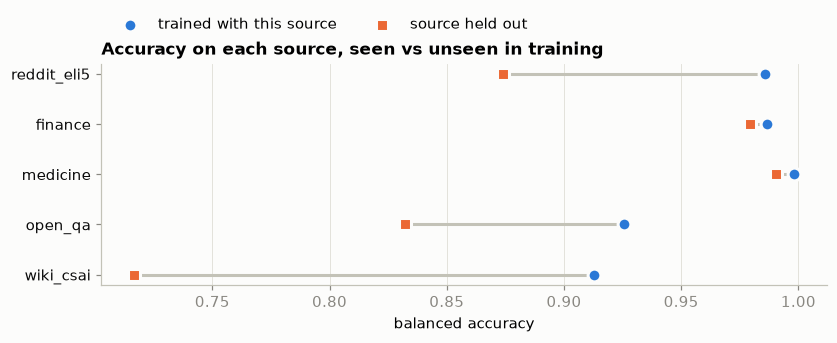

,balanced_accuracy,AUC,human_recall,chatgpt_recall,in_domain
reddit_eli5,0.874,0.962,0.984,0.764,0.986
finance,0.979,0.996,0.990,0.969,0.987
medicine,0.990,1.000,0.984,0.997,0.998
open_qa,0.832,0.937,0.939,0.725,0.926
wiki_csai,0.717,0.948,0.444,0.989,0.913


In [22]:
# Does it transfer? Train on four sources, test on the one left out.
transfer = {}
for s in SOURCES:
    train, test = clean[clean.source != s], clean[clean.source == s]
    fitted = model(**words_only).fit(train.norm, train.label.eq("chatgpt"))
    t = test.label.eq("chatgpt")
    pred = fitted.predict_proba(test.norm)[:, 1]
    transfer[s] = {"balanced_accuracy": balanced_accuracy_score(t, pred > .5), "AUC": roc_auc_score(t, pred),
                   "human_recall": (pred[~t] <= .5).mean(), "chatgpt_recall": (pred[t] > .5).mean()}
transfer = pd.DataFrame(transfer).T.assign(in_domain=results.loc["3. + normalised text, words only", SOURCES])

fig, ax = plt.subplots(figsize=(7.5, 3), layout="constrained")
pos = np.arange(5)
ax.hlines(pos, transfer.balanced_accuracy, transfer.in_domain, color="#c3c2b7", linewidth=2)
ax.scatter(transfer.in_domain, pos, s=70, color=HUMAN, label="trained with this source", zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.scatter(transfer.balanced_accuracy, pos, s=70, color=GPT, marker="s", label="source held out", zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.set_yticks(pos, SOURCES, color=INK); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="balanced accuracy", title="Accuracy on each source, seen vs unseen in training"); ax.legend(loc="lower left", ncols=2, bbox_to_anchor=(0, 1.08))
plt.show()
transfer.style.format("{:.3f}")

# Part 2: exploration for the project goal

Part 1 asked "can a classifier spot ChatGPT?".
The project asks a different question: **do LLMs build arguments the way humans do?**
This part checks whether HC3 can support the plan in `README.md`.

Nothing here is a graph result.
No extractor exists yet, so every number below describes raw text only.

This notebook prints HC3 and FiQA text, so its outputs are CC BY-SA 4.0.

## 9. Which subset can carry arguments? (Step 2)

`CLAUDE.md` allows `finance` or `wiki_csai`.
The README also asks for opinion questions.

In [23]:
SUBSETS = ["finance", "wiki_csai"]
sub = df[df.source.isin(SUBSETS)]
c2 = clean[clean.source.isin(SUBSETS)]
display(c2.groupby(["source", "label"]).words.agg(["count", "mean", "median"]).round(0).astype(int).unstack())
display(pd.DataFrame({
    "questions": sub.groupby("source").size(),
    "max human answers per question": sub.human_answers.map(len).groupby(sub.source).max(),
    "'Please explain what is' questions": sub.question.str.startswith("Please explain what is").groupby(sub.source).mean().map("{:.0%}".format),
}))

count          mean        median      
label     chatgpt human chatgpt human chatgpt human
source                                             
finance      4442  3932     206   175     206   128
wiki_csai     841   770     186   192     188   160

,questions,max human answers per question,'Please explain what is' questions
source,,,
finance,3933,1,0%
wiki_csai,842,1,100%


## 10. Opinion questions and the candidate pool (Step 2)

`OPINION` finds questions that ask for a judgement.
`PROCEDURAL` removes "how should I record this" questions, which have a factual answer.
A regex is only a first pass: **the team must read the final 50 questions.**

In [24]:
OPINION = r"(?i)\b(?:should (?:i|we)\b|is it (?:\w+ )?(?:better|worth|wise|a good|a bad|smart|ok|okay|advisable)|better to\b|worth it\b|good idea|bad idea|makes? sense|pros and cons)"
PROCEDURAL = r"(?i)\b(?:how|where|when|who)\b(?: \w+)? should\b|^how (?:long|much|many|high|do|does|can|to)\b"

fin = clean[clean.source.eq("finance")]
human_a = fin[fin.label.eq("human")].set_index("question").norm
gpt_all = fin[fin.label.eq("chatgpt") & ~fin.is_refusal].groupby("question").norm.first()  # ponytail: first ChatGPT answer only, 570 questions have two

questions = pd.DataFrame({"human_a": human_a}).join(gpt_all.rename("chatgpt"))
questions["opinion"] = questions.index.str.contains(OPINION) & ~questions.index.str.contains(PROCEDURAL)
n_words = lambda s: s.str.split().str.len()
in_range = lambda s: n_words(s).between(100, 300)
print("sample of questions the filter keeps (read these):")
print(questions[questions.opinion].sample(15, random_state=0).index.to_series().to_string(index=False))

sample of questions the filter keeps (read these):
question
                         Should I fund a move by borrowing or selling other property assets?
                 If our economy crashes, and cash is worthless, should i buy gold or silver 
                            Is working on a W2 basis, with benefits paid to me, a good idea?
Does it make sense to buy an index ETF (e.g. S&P 500) when the index is at an all-time high?
                        Should I pay cash or prefer a 0% interest loan for home furnishings?
         Should I try to hedge my emergency savings against currency and political concerns?
                            Should I finance a car to build credit for a mortgage next year?
                                                      Free brokerage vs paid - pros and cons
                               What should I be doing to protect myself from identity theft?
                 What college degree should I pursue to learn about stock and forex markets?
       Sho

## 11. The human-vs-human baseline (Steps 2 and 6)

`CLAUDE.md` requires a human-vs-human baseline for every result.
But section 9 shows HC3 keeps **one** human answer per question in both allowed subsets,
so HC3 alone can't give a same-question baseline.

HC3 `finance` comes from FiQA, and FiQA keeps more answers per question.
This cell checks that link, then adds a second human answer.

In [25]:
fq = load_dataset("BeIR/fiqa", "queries", split="queries").to_pandas()
fc = load_dataset("BeIR/fiqa", "corpus", split="corpus").to_pandas()
qrels = load_dataset("BeIR/fiqa-qrels")
qrels = pd.concat([qrels[s].to_pandas() for s in qrels]).astype({"query-id": str, "corpus-id": str})

key = lambda s: s.str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
fiqa = (qrels.merge(fq.assign(q=key(fq.text))[["_id", "q"]], left_on="query-id", right_on="_id")
             .merge(fc.assign(a=key(fc.text), norm=normalise(fc.text))[["_id", "a", "norm"]], left_on="corpus-id", right_on="_id"))
hc3 = df[df.source.eq("finance")].assign(q=lambda d: key(d.question), a=lambda d: key(d.human_answers.str[0]))
print(f"HC3 finance questions found in FiQA: {hc3.q.isin(set(fiqa.q)).mean():.1%}")
print(f"HC3 human answers that are exactly one FiQA answer: {hc3.set_index(['q', 'a']).index.isin(fiqa.set_index(['q', 'a']).index).mean():.1%}")
n_answers = hc3.q.map(fiqa.groupby("q").size())
print(f"HC3 finance questions with 2+ FiQA answers: {n_answers.ge(2).mean():.1%}")

# Second human answer: the in-range FiQA answer closest in length to the HC3 one, so length differs as little as possible.
others = fiqa[in_range(fiqa.norm)].assign(w=lambda d: n_words(d.norm))
hc3_key = hc3.set_index("question")
questions["q"], questions["a"] = hc3_key.q.reindex(questions.index), hc3_key.a.reindex(questions.index)
target = questions.assign(wa=n_words(questions.human_a)).reset_index()[["question", "q", "a", "wa"]]
cand = target.merge(others[["q", "a", "norm", "w"]], on="q", suffixes=("", "_b")).query("a != a_b")
best = cand.assign(gap=(cand.w - cand.wa).abs()).sort_values(["gap", "norm"]).groupby("question").norm.first()
questions["human_b"] = best

funnel = [("finance questions", questions.index.notna()), ("+ opinion question", questions.opinion),
          ("+ human A has 100-300 words", in_range(questions.human_a)),
          ("+ usable ChatGPT answer, 100-300 words", questions.chatgpt.notna() & in_range(questions.chatgpt.fillna(""))),
          ("+ second human answer, 100-300 words", questions.human_b.notna())]
mask, rows = np.ones(len(questions), bool), []
for name, m in funnel:
    mask = mask & np.asarray(m); rows.append((name, mask.sum()))
pool = questions[mask].copy()
display(pd.DataFrame(rows, columns=["filter", "questions left"]))
assert len(pool) >= 50, "pool too small for the README's 50 questions"
display(pool[["human_a", "human_b", "chatgpt"]].apply(n_words).describe().round(0).astype(int).loc[["min", "25%", "50%", "75%", "max"]])

HC3 finance questions found in FiQA: 100.0%
HC3 human answers that are exactly one FiQA answer: 100.0%
HC3 finance questions with 2+ FiQA answers: 61.9%


,filter,questions left
0,finance questions,3932
1,+ opinion question,228
2,+ human A has 100-300 words,106
3,"+ usable ChatGPT answer, 100-300 words",99
4,"+ second human answer, 100-300 words",68


,human_a,human_b,chatgpt
min,100,101,124
25%,146,132,191
50%,184,185,216
75%,231,221,245
max,295,298,289


## 12. Sentence splitting (Step 3)

One sentence is one node, so the splitter sets graph size.
ChatGPT text lost its line breaks when it was scraped.
`purposes.An LLC` is really two sentences, and a plain split on "punctuation + space" misses them.
This damage is **one-sided**, so it would look like a human-vs-LLM difference.

In [26]:
GLUE = {"sentence glue (.An)": r"[a-z0-9)\"%][.!?][A-Z][a-z]", "list glue (:An)": r"[a-z]:[A-Z]",
        "run-together items (shareSale)": r"[a-z]{3}[A-Z][a-z]{2}", "double space in raw text": r"  "}
fin_raw = raw[raw.source.isin(SUBSETS) & ~raw.is_error]
display(pd.DataFrame({k: fin_raw.text.str.contains(v).groupby([fin_raw.source, fin_raw.label]).mean() for k, v in GLUE.items()}).style.format("{:.1%}"))

ABBREV = r"\b(?:e\.g|i\.e|etc|vs|Mr|Mrs|Ms|Dr|Inc|Ltd|Co|Corp|No|St|approx|U\.S|U\.K)\."
LIST_NUMBER = r"(?:^|(?<=[.!?:,] ))\d{1,2}\.(?=\s)"  # only a number that opens a sentence, so "turn 65. If" still splits

def split_sentences(text):
    text = re.sub(r"(?<=[a-z0-9)\"%])([.!?])(?=[A-Z][a-z])", r"\1 ", text)  # repair sentence glue
    text = re.sub(r"(?<=[a-z]):(?=[A-Z])", ": ", text)
    hide = lambda m: m.group().replace(".", "\0")
    text = re.sub(LIST_NUMBER, hide, re.sub(ABBREV, hide, text))
    parts = re.split(r"(?<=[.!?])\s+|(?<=[.!?][\"')\]])\s+", text)
    return [p.replace("\0", ".").strip() for p in parts if p.strip()]

for text, want in [
    ("It is taxed.An LLC is not.", ["It is taxed.", "An LLC is not."]),
    ("Buy e.g. bonds in the U.S. market. Then wait!", ["Buy e.g. bonds in the U.S. market.", "Then wait!"]),
    ("1. Save money. 2. Invest it.", ["1. Save money.", "2. Invest it."]),
    ('He said "stop." Then left.', ['He said "stop."', "Then left."]),
    ("It costs $2.50 at Node.js. Yes.", ["It costs $2.50 at Node.js.", "Yes."]),
    ("You qualify at 65. If not, wait.", ["You qualify at 65.", "If not, wait."]),
]:
    assert split_sentences(text) == want, (text, split_sentences(text))

naive = lambda t: [s for s in SENT.split(t) if s.strip()]  # the Part 1 splitter
long_pool = pool[["human_a", "human_b", "chatgpt"]].melt(var_name="author", value_name="text", ignore_index=False).rename_axis("question").reset_index()
long_pool["nodes_naive"] = long_pool.text.map(lambda t: len(naive(t)))
long_pool["nodes"] = long_pool.text.map(lambda t: len(split_sentences(t)))
long_pool["words"] = n_words(long_pool.text)
long_pool["words_per_node"] = long_pool.words / long_pool.nodes
long_pool.groupby("author")[["nodes_naive", "nodes", "words", "words_per_node"]].median().round(1)

,nodes_naive,nodes,words,words_per_node
author,,,,
chatgpt,6.0,9.0,216.5,24.2
human_a,9.0,9.0,184.5,19.5
human_b,9.0,9.0,185.0,18.8


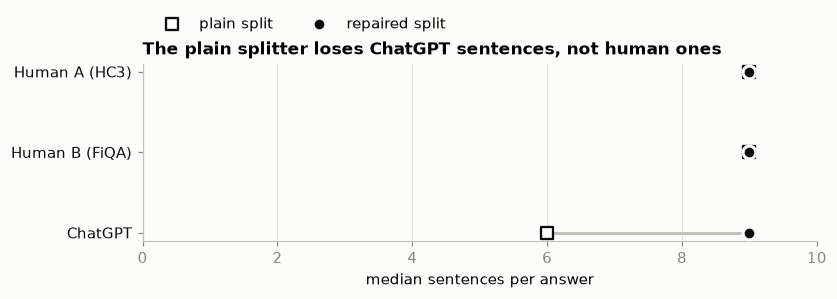

In [27]:
NAMES = {"human_a": "Human A (HC3)", "human_b": "Human B (FiQA)", "chatgpt": "ChatGPT"}
SERIES = {"human_a": HUMAN, "human_b": "#1a9e8f", "chatgpt": GPT}
med = long_pool.groupby("author")[["nodes_naive", "nodes"]].median().loc[list(NAMES)]
fig, ax = plt.subplots(figsize=(7.5, 2.6), layout="constrained")
pos = np.arange(3)
ax.hlines(pos, med.nodes_naive, med.nodes, color="#c3c2b7", linewidth=2)
ax.scatter(med.nodes_naive, pos, s=70, marker="s", facecolor="#fcfcfb", edgecolor=INK, linewidth=1.5, label="plain split", zorder=3)
ax.scatter(med.nodes, pos, s=70, color=INK, edgecolor="#fcfcfb", linewidth=2, label="repaired split", zorder=3)
ax.set_yticks(pos, list(NAMES.values()), color=INK); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="median sentences per answer", xlim=(0, 10), title="The plain splitter loses ChatGPT sentences, not human ones")
ax.legend(loc="lower left", ncols=2, bbox_to_anchor=(0, 1.1)); plt.show()

In [28]:
# Does the Part 1 sentence result survive the repair? 0.5 means no difference between authors.
def variation(parts):
    n = [len(s.split()) for s in parts]
    return np.std(n) / max(np.mean(n), 1) if len(n) > 2 else np.nan

check = {}
for name, fn in [("plain split", naive), ("repaired split", split_sentences)]:
    parts = clean.norm.map(fn)
    v = pd.DataFrame({"sentences": parts.map(len), "words per sentence": clean.words / parts.map(len).clip(lower=1), "sentence length variation": parts.map(variation)})
    for col in v:
        check[(col, name)] = {s: roc_auc_score(y[m], v.loc[m, col]) for s in SOURCES for m in [clean.source.eq(s) & v[col].notna()]}
pd.DataFrame(check).T.round(3)

,,reddit_eli5,finance,medicine,open_qa,wiki_csai
sentences,plain split,0.728,0.407,0.805,0.984,0.535
words per sentence,plain split,0.743,0.928,0.658,0.413,0.556
sentence length variation,plain split,0.261,0.393,0.109,0.085,0.215
sentences,repaired split,0.741,0.590,0.715,0.981,0.544
words per sentence,repaired split,0.728,0.743,0.861,0.434,0.524
sentence length variation,repaired split,0.228,0.185,0.102,0.292,0.217


## 13. Chunking edge cases, with numbers (Step 1)

The README lists open questions for `GUIDE.md`.
These counts show how often each one comes up in the pool.

In [29]:
sents = long_pool.assign(sentence=long_pool.text.map(split_sentences)).explode("sentence")
sents["n"] = sents.sentence.str.split().str.len()
edge = pd.DataFrame({
    "very short (3 words or fewer)": sents.n.le(3),
    "very long (over 50 words)": sents.n.gt(50),
    "two ideas (', but' or '; however')": sents.sentence.str.contains(r"(?i), but\b|; however\b"),
    "is a question": sents.sentence.str.endswith("?"),
    "numbered list item": sents.sentence.str.match(r"\d{1,2}\. "),
    "colon list lead-in": sents.sentence.str.contains(r":\s*$|: [A-Z]"),
}).groupby(sents.author).mean().T[list(NAMES)].rename(columns=NAMES)
display(edge.style.format("{:.1%}"))

CONTEXT = {"mentions other answers or comments": r"(?i)\b(?:other answers?|answers? above|above answers?|as others|previous answer|comments?\b)",
           "EDIT or UPDATE note": r"(?:^|\s)(?:EDIT|Edit|UPDATE|Update):", "dangling link ('see here')": r"(?i)\b(?:see|read|look|click|found|check) (?:it )?here\b",
           "addresses a person (@name)": r"@\w+"}
display(pd.DataFrame({k: long_pool.text.str.contains(v).groupby(long_pool.author).mean() for k, v in CONTEXT.items()}).T[list(NAMES)].rename(columns=NAMES).style.format("{:.1%}"))

author,Human A (HC3),Human B (FiQA),ChatGPT
very short (3 words or fewer),2.2%,1.9%,0.0%
very long (over 50 words),1.4%,1.8%,1.0%
"two ideas (', but' or '; however')",3.7%,5.0%,2.3%
is a question,3.9%,7.5%,3.4%
numbered list item,0.0%,0.0%,0.0%
colon list lead-in,3.0%,3.1%,20.1%


author,Human A (HC3),Human B (FiQA),ChatGPT
mentions other answers or comments,1.5%,4.4%,0.0%
EDIT or UPDATE note,0.0%,0.0%,0.0%
dangling link ('see here'),0.0%,0.0%,0.0%
addresses a person (@name),0.0%,1.5%,0.0%


## 14. Giveaway lines and blind labelling (Steps 2 and 4)

Step 2 removes lines like "As an AI".
Step 4 hides which text is which, so the labellers must not be able to tell from formatting.
The AI disclaimer row is 0% by construction: section 10 already removed flagged refusals from the pool.

In [30]:
TELLS = {"AI disclaimer": r"(?i)\bas an ai\b|language model", "opens with apology": r"(?i)^(?:i'm|i am) sorry", "'it is important to'": r"(?i)\bit(?: is|'s) important to\b",
         "'consult a professional'": r"(?i)\bconsult (?:with )?(?:a|an|your)\b", "first person (I, my)": r"\b(?:I|I'm|I've|my|My)\b", "glue left after repair": r"[a-z]{3}[A-Z][a-z]{2}"}
tells = pd.DataFrame({k: long_pool.text.str.contains(v).groupby(long_pool.author).mean() for k, v in TELLS.items()}).T[list(NAMES)].rename(columns=NAMES)
tells.style.format("{:.1%}")

author,Human A (HC3),Human B (FiQA),ChatGPT
AI disclaimer,0.0%,0.0%,0.0%
opens with apology,0.0%,0.0%,0.0%
'it is important to',0.0%,0.0%,55.9%
'consult a professional',0.0%,0.0%,23.5%
"first person (I, my)",73.5%,76.5%,0.0%
glue left after repair,0.0%,1.5%,1.5%


## 15. Surface cues, next to the baseline (hypotheses for Step 5)

Cue words are **not** relations.
"But" does not always mean `attacks`.
These numbers only suggest what to look for once the extractor works.

Each row compares two gaps on the same question:
human A vs human B (the baseline) and human A vs ChatGPT.
If the two gaps are close, there is no sign of a difference.
The interval is a 95% bootstrap over questions.

In [31]:
CUES = {"supports": r"\b(?:because|since|therefore|thus|as a result|so that)\b", "attacks": r"\b(?:but|however|although|though|on the other hand|nevertheless)\b",
        "example": r"\b(?:for example|for instance|e\.g\.|such as)\b", "restates": r"\b(?:in short|in summary|overall|in other words|to sum up)\b"}
sents["low"] = sents.sentence.str.lower()
cue = pd.DataFrame({k: sents.low.str.contains(v) for k, v in CUES.items()}).groupby([sents.question, sents.author]).mean()
per_answer = cue.join(long_pool.set_index(["question", "author"])[["nodes", "words_per_node"]])

def gaps(col, seed=0, reps=2000):
    w = per_answer[col].unstack()
    ab, ac = (w.human_a - w.human_b).abs().to_numpy(), (w.human_a - w.chatgpt).abs().to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(w), (reps, len(w)))
    lo, hi = np.percentile((ac - ab)[idx].mean(1), [2.5, 97.5])
    return {"Human A": w.human_a.mean(), "Human B": w.human_b.mean(), "ChatGPT": w.chatgpt.mean(),
            "gap A-B (baseline)": ab.mean(), "gap A-ChatGPT": ac.mean(), "extra gap": (ac - ab).mean(), "95% low": lo, "95% high": hi}

surface = pd.DataFrame({c: gaps(c) for c in ["nodes", "words_per_node", *CUES]}).T
display(surface.round(3))
print(f"{len(per_answer) // 3} questions. Cue rows are the share of an answer's sentences containing a cue word.")

,Human A,Human B,ChatGPT,gap A-B (baseline),gap A-ChatGPT,extra gap,95% low,95% high
nodes,10.221,9.941,8.985,3.868,3.794,-0.074,-0.868,0.735
words_per_node,20.158,19.926,24.748,6.311,6.749,0.438,-1.564,2.744
supports,0.062,0.051,0.026,0.080,0.076,-0.005,-0.024,0.015
attacks,0.110,0.135,0.104,0.131,0.111,-0.019,-0.060,0.020
example,0.012,0.012,0.086,0.021,0.088,0.066,0.040,0.093
restates,0.008,0.005,0.035,0.010,0.032,0.022,0.008,0.036


68 questions. Cue rows are the share of an answer's sentences containing a cue word.


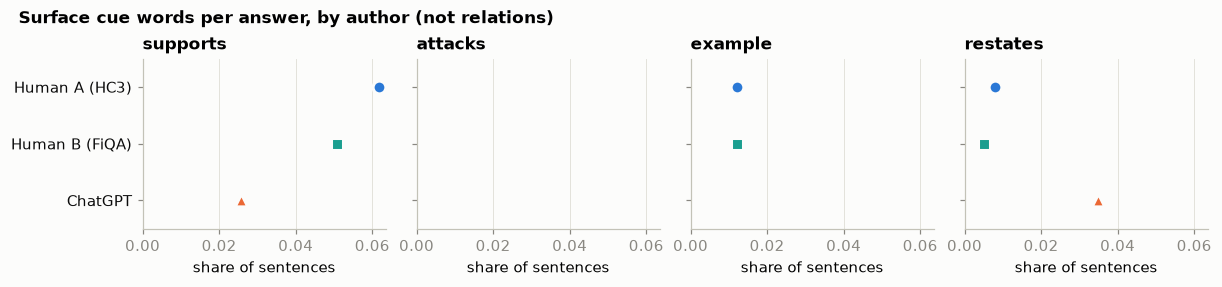

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.5), sharex=True, sharey=True, layout="constrained")
for ax, c in zip(axes, CUES):
    for i, (k, name) in enumerate(NAMES.items()):
        v = surface.loc[c, name.split(" (")[0]]
        ax.scatter(v, i, s=70, color=SERIES[k], edgecolor="#fcfcfb", linewidth=2, zorder=3, marker="os^"[i], label=name)
    ax.set(title=c, xlabel="share of sentences", xlim=(0, None)); ax.grid(axis="y", visible=False); ax.margins(y=.25)
axes[0].set_yticks(range(3), list(NAMES.values()), color=INK); axes[0].invert_yaxis()
fig.suptitle("Surface cue words per answer, by author (not relations)", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.show()

## 16. Read real examples

`CLAUDE.md` says to read 3 real examples before claiming a difference.
Any claim about the pool has to survive this read.

In [33]:
for q, row in pool.sample(3, random_state=7).iterrows():
    print("=" * 100, f"\nQ: {q}")
    for k, name in NAMES.items():
        parts = split_sentences(row[k])
        print(f"\n[{name}: {len(parts)} sentences]")
        for i, s in enumerate(parts, 1): print(f"  {i}. {s}")

Q: What should I do with the change in my change-jar?

[Human A (HC3): 4 sentences]
  1. I don't know if those machines work this way in the UK too, but here in the US you can often avoid the coin-counting fee if you opt to convert the money into a gift certificate instead of cash.
  2. I routinely convert my coins to Amazon gift certificate money with no charge.
  3. Individual machines differ in which particular gift cards they use, but at the least, almost all of them offer the option for a no-fee conversion to a voucher/gift certificate to the store where the machine is.
  4. So it's likely you'd be able to use the machine to convert the cash to "money" you can use to buy groceries.

[Human B (FiQA): 7 sentences]
  1. Are you in an occupation that regularly collects change or is this change left in your pocket at the end of the day?
  2. Here in the US it is typically worth it to invest in some automatic coin counters if you are in an occupation that regularly collects coins.
  3. 